# VARANASI — Qiskit Fall Fest 2026 (Phase 2)
## Problem Statement PS-O1: Quantum Optimization of Network Partitioning Using QAOA

---
- **Registered Team Name:** `VARANASI`
- **Official Participant / Team ID:** `AP251100708044`
- **Team Leader:** Ganesh Pirinti (SRM University-AP, Andhra Pradesh | `ganeshpirinti95218@gmail.com`)
- **Team Member:** Mohammed Sadiq (SRM University-AP, Andhra Pradesh | `sadiqmohammedkhan12@gmail.com`)
- **Host Institution:** SRM University-AP | Hackathon & Competitions Cell
- **Problem Statement Code:** `PS-O1` (Network Partitioning / Max-Cut)
- **GitHub Repository URL:** `https://github.com/ganesh-pirinti/VARANASI_PROJECTQ`
- **Submission Scope:** Phase 2 (Optimization Track) — End-to-End Execution, Processor D Co-Design, and Architectural Benchmarking

---
### Notebook Objectives
1. **Mathematical Rigor:** Formulate Network Partitioning as a QUBO and derive the exact Ising cost Hamiltonian.
2. **Exact Classical Baseline:** Exhaustively evaluate all $2^6 = 64$ bitstrings to establish $C^* = 22$, all optimal partitions, and the uniform random baseline.
3. **Objective 1 (Bell-State Tomography):** Verify state preparation of $|\Phi^+angle$ on Processor D for adjacent ($d=1$) and distant ($d=4$) pairs under ideal and noisy simulation ($4096$ shots/basis).
4. **Objective 2 (Processor D Co-Design):** Verify compliance with official design rules via `validate_processor_d()`, resolving Processor B's SWAP routing bottleneck.
5. **Objective 3 (QAOA Benchmarking):** Implement QAOA ($p=1$) with multi-restart classical optimization (seeds `[0,1,2,3,4]`), benchmark across Processors A, B, and D (ideal & noisy), and quantify approximation ratio $r$, sampling probability $P_{opt}$, and gate overhead.


In [1]:
# Section 1: Environment Setup, Official Settings, and Verification
import os
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import qiskit
from qiskit import QuantumCircuit
import qiskit_aer
from qiskit_aer import AerSimulator

import qff_phase2
from qff_phase2 import (
    BASIS_GATES,
    OPT_LEVEL,
    SEED,
    SHOTS,
    P1_DEPOL,
    P2_DEPOL,
    P_READOUT,
    PROCESSOR_A,
    PROCESSOR_B,
    load_processor,
    validate_processor_d,
    circuit_metrics,
    transpile_for,
    simulator,
    bell_experiment,
    counts_to_x,
    coupling_map_from_edges,
)
from src.exact_solver import load_pso1_instance, solve_exact_maxcut
from src.qaoa_solver import QAOASolver, construct_qaoa_circuit
from src.bell_evaluator import run_bell_verification
from src.benchmark_runner import run_all_benchmarks

print("=== Qiskit Fall Fest 2026 Environment Verification ===")
print(f"Python Version    : {sys.version.split()[0]}")
print(f"Qiskit Version    : {qiskit.__version__}")
print(f"Qiskit Aer Version: {qiskit_aer.__version__}")
print(f"Basis Gates       : {BASIS_GATES}")
print(f"Transpilation Opt : Level {OPT_LEVEL} (SABRE Layout & Routing, Seed {SEED})")
print(f"Simulator Shots   : {SHOTS} (Seed {SEED})")
print(f"Official Noise    : p1={P1_DEPOL}, p2={P2_DEPOL}, p_readout={P_READOUT}")


=== Qiskit Fall Fest 2026 Environment Verification ===
Python Version    : 3.14.6
Qiskit Version    : 2.5.2
Qiskit Aer Version: 0.17.2
Basis Gates       : ['rz', 'sx', 'x', 'cx']
Transpilation Opt : Level 1 (SABRE Layout & Routing, Seed 42)
Simulator Shots   : 4096 (Seed 42)
Official Noise    : p1=0.001, p2=0.005, p_readout=0.01


# Section 2: Mathematical Formulation and QUBO Construction

### 2.1 Problem Formulation
We are given a locked weighted network $G = (V, E, w)$ with $|V| = 6$ vertices and $|E| = 9$ edges, where edge weights $w_{uv} \in \{1, \dots, 5\}$. The goal is to partition the network into two disjoint sets $S$ and $ar{S} = V \setminus S$ such that the total weight of cut edges across the partition is maximized.

Assign a binary decision variable $x_i \in \{0, 1\}$ to each vertex $i \in V$, where:
$$
x_i = \begin{cases} 1 & \text{if } i \in S \\ 0 & \text{if } i \in \bar{S} \end{cases}
$$
An edge $(u, v) \in E$ is cut if and only if $x_u 
eq x_v$. The cut weight indicator is:
$$
x_u + x_v - 2 x_u x_v = (x_u - x_v)^2 = \begin{cases} 1 & \text{if } x_u \neq x_v \\ 0 & \text{if } x_u = x_v \end{cases}
$$
The total cut weight objective function is:
$$
C(x) = \sum_{(u, v) \in E} w_{uv} (x_u + x_v - 2 x_u x_v)
$$
In standard Quadratic Unconstrained Binary Optimization (QUBO) minimization form:
$$
\min_{x \in \{0, 1\}^6} Q(x) = -C(x) = \sum_{(u, v) \in E} w_{uv} (2 x_u x_v - x_u - x_v)
$$

### 2.2 Ising Cost Hamiltonian Derivation
Using the canonical mapping from binary variables to Pauli-$Z$ operators:
$$
x_i = \frac{I - Z_i}{2}
$$
Substituting this into the cut expression yields:
$$
x_u + x_v - 2 x_u x_v = \frac{I - Z_u}{2} + \frac{I - Z_v}{2} - 2 \left(\frac{I - Z_u}{2}\right)\left(\frac{I - Z_v}{2}\right) = \frac{I - Z_u Z_v}{2}
$$
Thus, the total cut operator is:
$$
\hat{C} = \sum_{(u, v) \in E} \frac{w_{uv}}{2} (I - Z_u Z_v) = \frac{W}{2} I - \sum_{(u, v) \in E} \frac{w_{uv}}{2} Z_u Z_v
$$
where $W = \sum_{(u, v) \in E} w_{uv} = 27$ is the sum of all edge weights.
Discarding the constant energy offset $\frac{W}{2} I$, the cost Hamiltonian to minimize is:
$$
\hat{H}_C = \sum_{(u, v) \in E} \frac{w_{uv}}{2} Z_u Z_v
$$
The transverse field mixer Hamiltonian is:
$$
\hat{H}_M = \sum_{i=0}^5 X_i
$$
The QAOA state with depth $p=1$ parameterized by $(\gamma, \beta)$ is:
$$
|\psi(\gamma, \beta)\rangle = e^{-i \beta \hat{H}_M} e^{-i \gamma \hat{H}_C} |+\rangle^{\otimes 6} = \prod_{i=0}^5 R_X(2\beta) \prod_{(u, v) \in E} R_{ZZ}(w_{uv} \gamma) |+\rangle^{\otimes 6}
$$


In [2]:
# Section 3: Exact Classical Baseline and Ground Truth Enumeration
inst = load_pso1_instance("data/instance.json")
weighted_edges = inst["weighted_edges"]
num_vertices = inst["num_vertices"]

exact_res = solve_exact_maxcut(weighted_edges, num_vertices)
c_star = exact_res["max_cut_weight"]
total_weight = exact_res["total_graph_weight"]
optimal_partitions = exact_res["optimal_partitions"]
mean_random = exact_res["uniform_random_mean_cut"]
r_random = exact_res["uniform_random_approx_ratio"]
p_opt_random = exact_res["uniform_random_p_opt"]

print("=== PS-O1 Exact Classical Baseline ===")
print(f"Number of Vertices          : {num_vertices}")
print(f"Number of Edges             : {len(weighted_edges)}")
print(f"Total Graph Weight W        : {total_weight}")
print(f"Maximum Cut Weight C*       : {c_star} (out of {total_weight})")
print(f"Optimal Solution Count      : {len(optimal_partitions)} / {1 << num_vertices} states")
print(f"Uniform Random Mean Cut     : {mean_random:.4f}")
print(f"Uniform Random Approx Ratio : {r_random:.4f}")
print(f"Uniform Random P_opt        : {p_opt_random:.4f} ({p_opt_random*100:.2f}%)")
print("\nOptimal Partitions (x0, x1, x2, x3, x4, x5):")
for p in optimal_partitions:
    group_s = [i for i, b in enumerate(p) if b == 1]
    group_sbar = [i for i, b in enumerate(p) if b == 0]
    print(f"  Assignment {p} -> S={group_s}, S_bar={group_sbar}")


=== PS-O1 Exact Classical Baseline ===
Number of Vertices          : 6
Number of Edges             : 9
Total Graph Weight W        : 27
Maximum Cut Weight C*       : 22 (out of 27)
Optimal Solution Count      : 2 / 64 states
Uniform Random Mean Cut     : 13.5000
Uniform Random Approx Ratio : 0.6136
Uniform Random P_opt        : 0.0312 (3.12%)

Optimal Partitions (x0, x1, x2, x3, x4, x5):
  Assignment (1, 1, 0, 1, 0, 0) -> S=[0, 1, 3], S_bar=[2, 4, 5]
  Assignment (0, 0, 1, 0, 1, 1) -> S=[2, 4, 5], S_bar=[0, 1, 3]


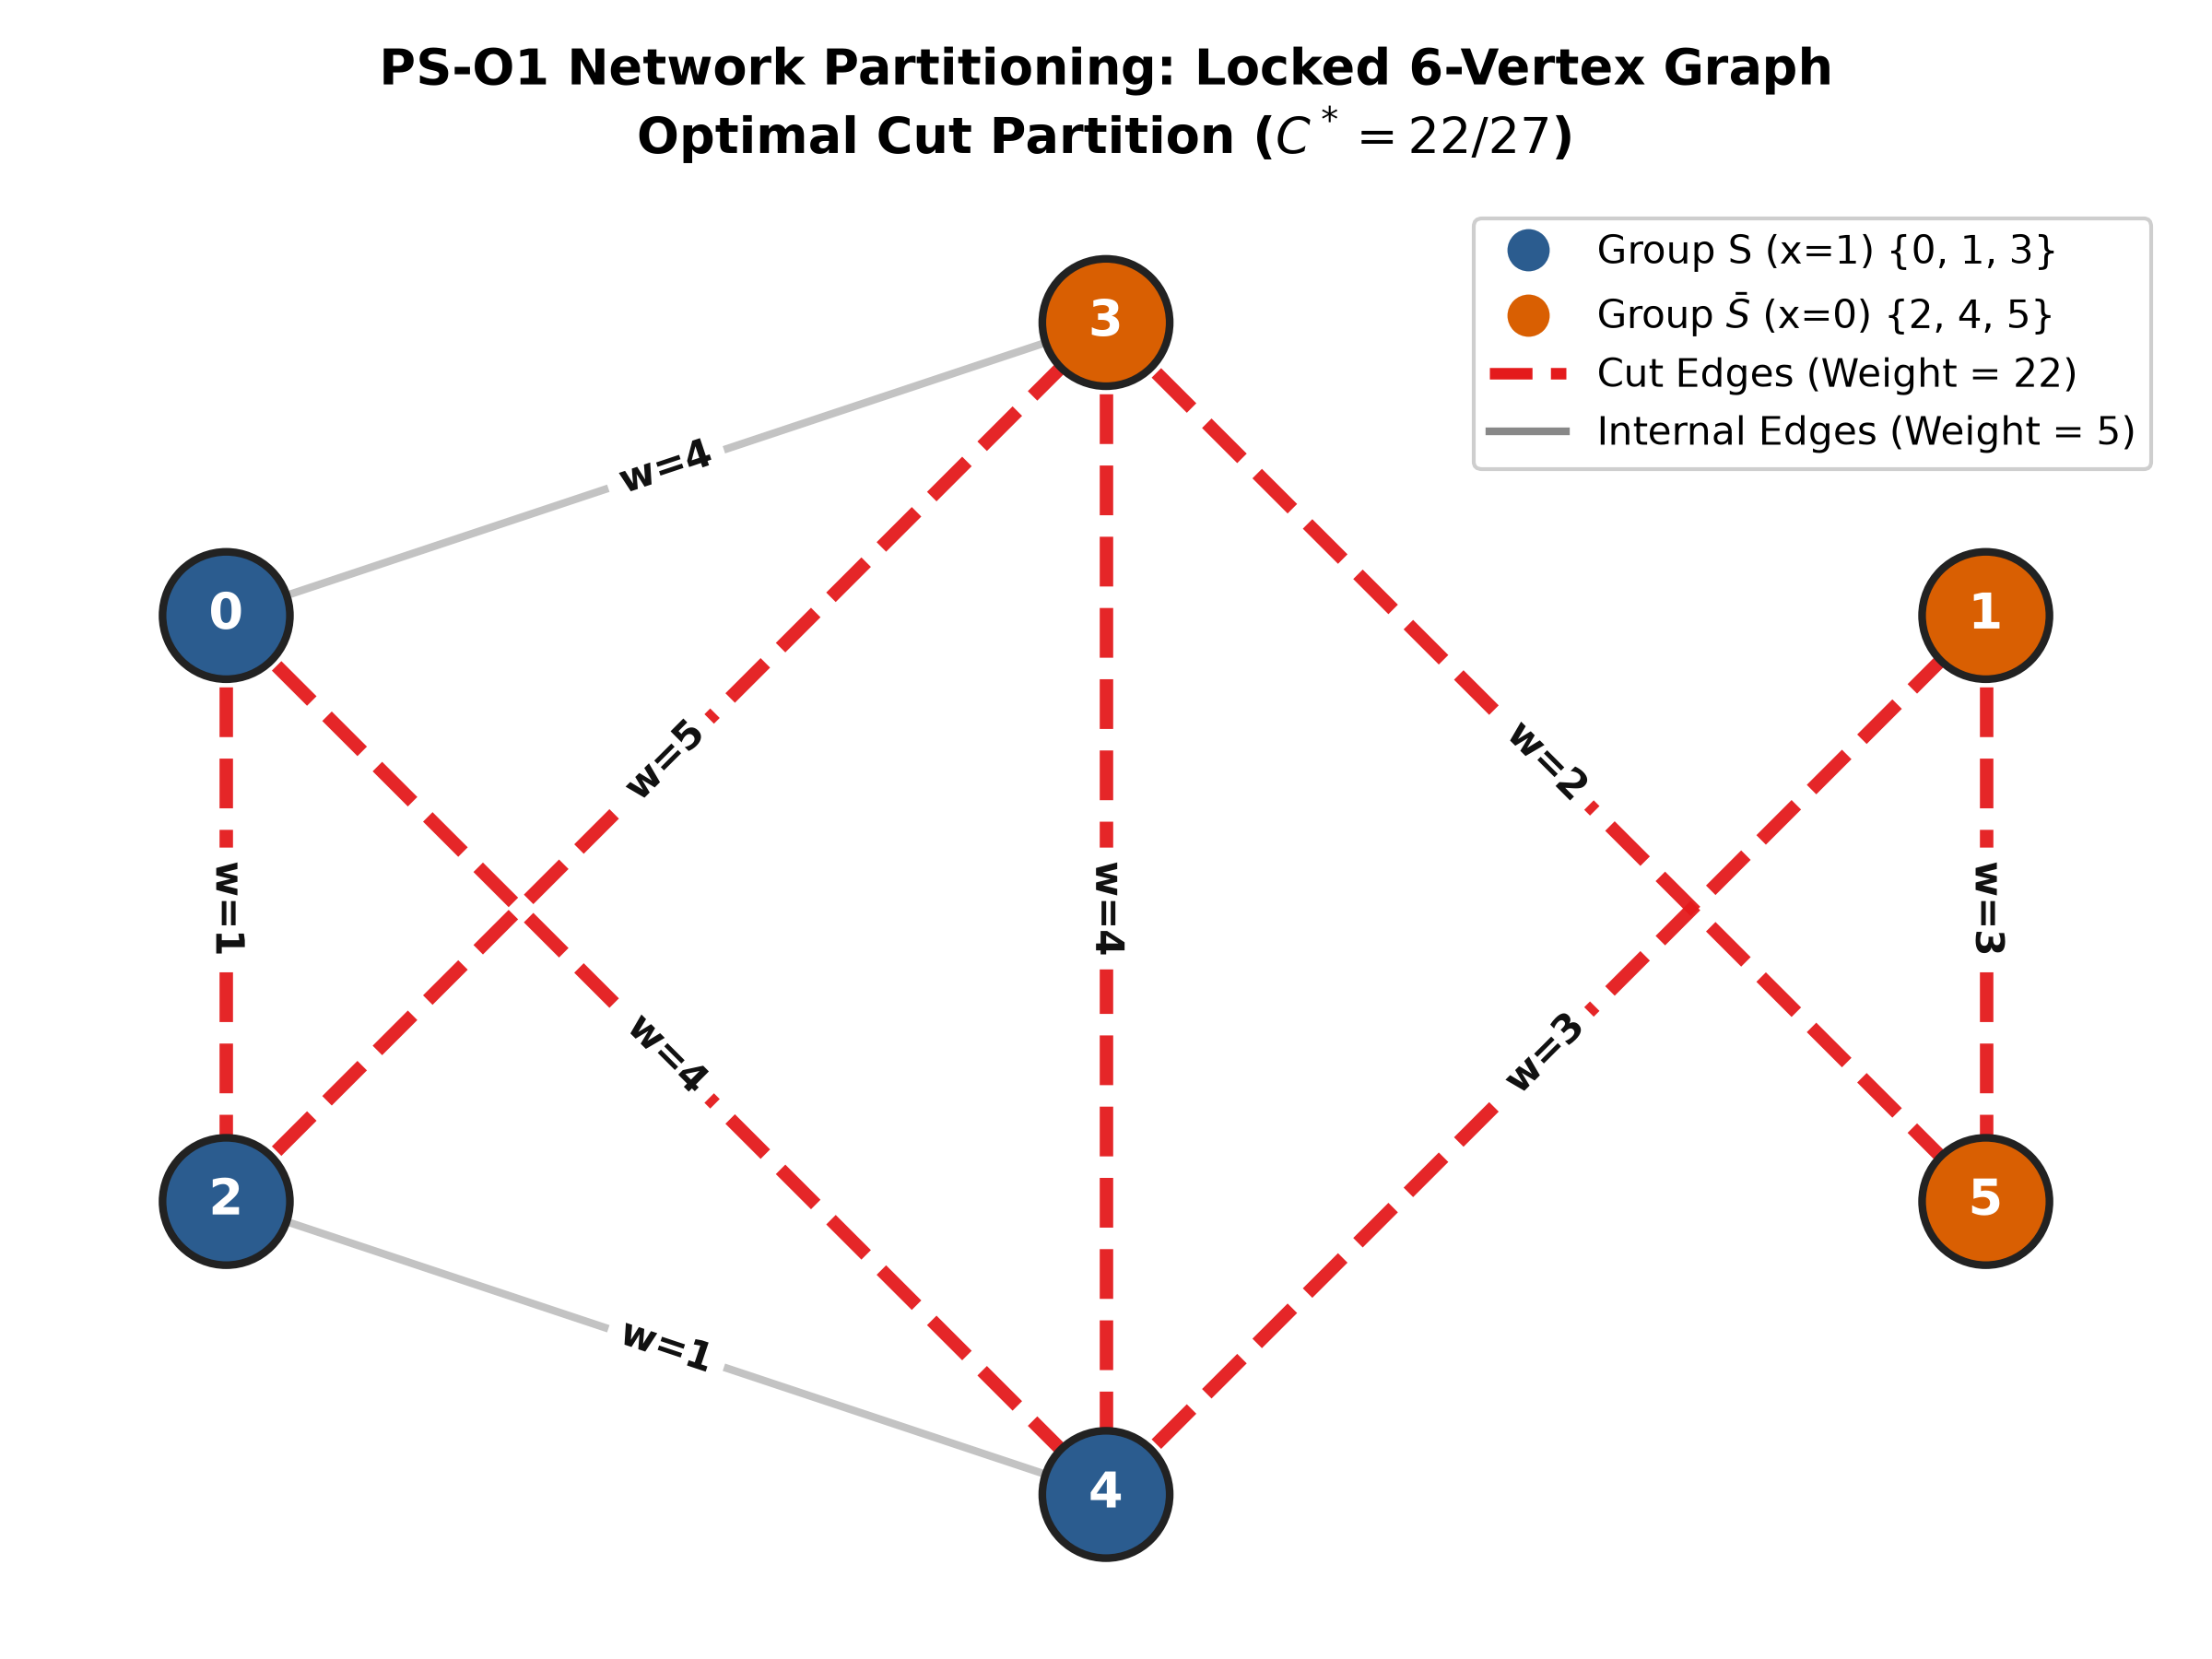

In [3]:
# Section 4: Visualizing the Network Partitioning Graph and Optimal Cut
from src.visualizations import plot_network_partitioning_graph
from IPython.display import Image, display

fig_graph_path = "results/figures/network_partitioning_graph.png"
plot_network_partitioning_graph(weighted_edges, optimal_partitions[0], fig_graph_path)
display(Image(filename=fig_graph_path))


# Section 5: Objective 1 — Bell-State Preparation and Verification on Processor D

The target maximally entangled Bell state is:
$$
|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}
$$
State preparation uses $H$ on the control qubit followed by $CX$ between control and target qubits.
Measurements are performed in three complementary correlation bases:
- **$ZZ$ Basis:** Standard computational basis (no rotation gates).
- **$XX$ Basis:** Hadamard gates applied to both qubits prior to measurement.
- **$YY$ Basis:** $S^\dagger$ followed by Hadamard applied to both qubits prior to measurement.

The fidelity $F$ is calculated via:
$$
F(|\Phi^+\rangle) = \frac{1 + \langle XX \rangle - \langle YY \rangle + \langle ZZ \rangle}{4}
$$
We benchmark two pairs on Processor D:
1. **Near Pair:** Directly adjacent physical qubits (distance $d=1$), using $(0, 2)$.
2. **Far Pair:** Maximally distant physical qubits (graph diameter $d=4$), using $(0, 7)$.


=== Bell State Verification Results (results/tables/bell.csv) ===


,pair_type,qubit_pair,pair_distance,condition,cx_count,exp_XX,exp_YY,exp_ZZ,fidelity,fidelity_se
0,near,"(0,2)",1,ideal,1,1.000000,-1.000000,1.000000,1.000000,0.000000
1,near,"(0,2)",1,noisy,1,0.945801,-0.952148,0.955078,0.963257,0.002092
2,far,"(0,7)",4,ideal,10,1.000000,-1.000000,1.000000,1.000000,0.000000
3,far,"(0,7)",4,noisy,10,0.924316,-0.903809,0.939941,0.942017,0.002607


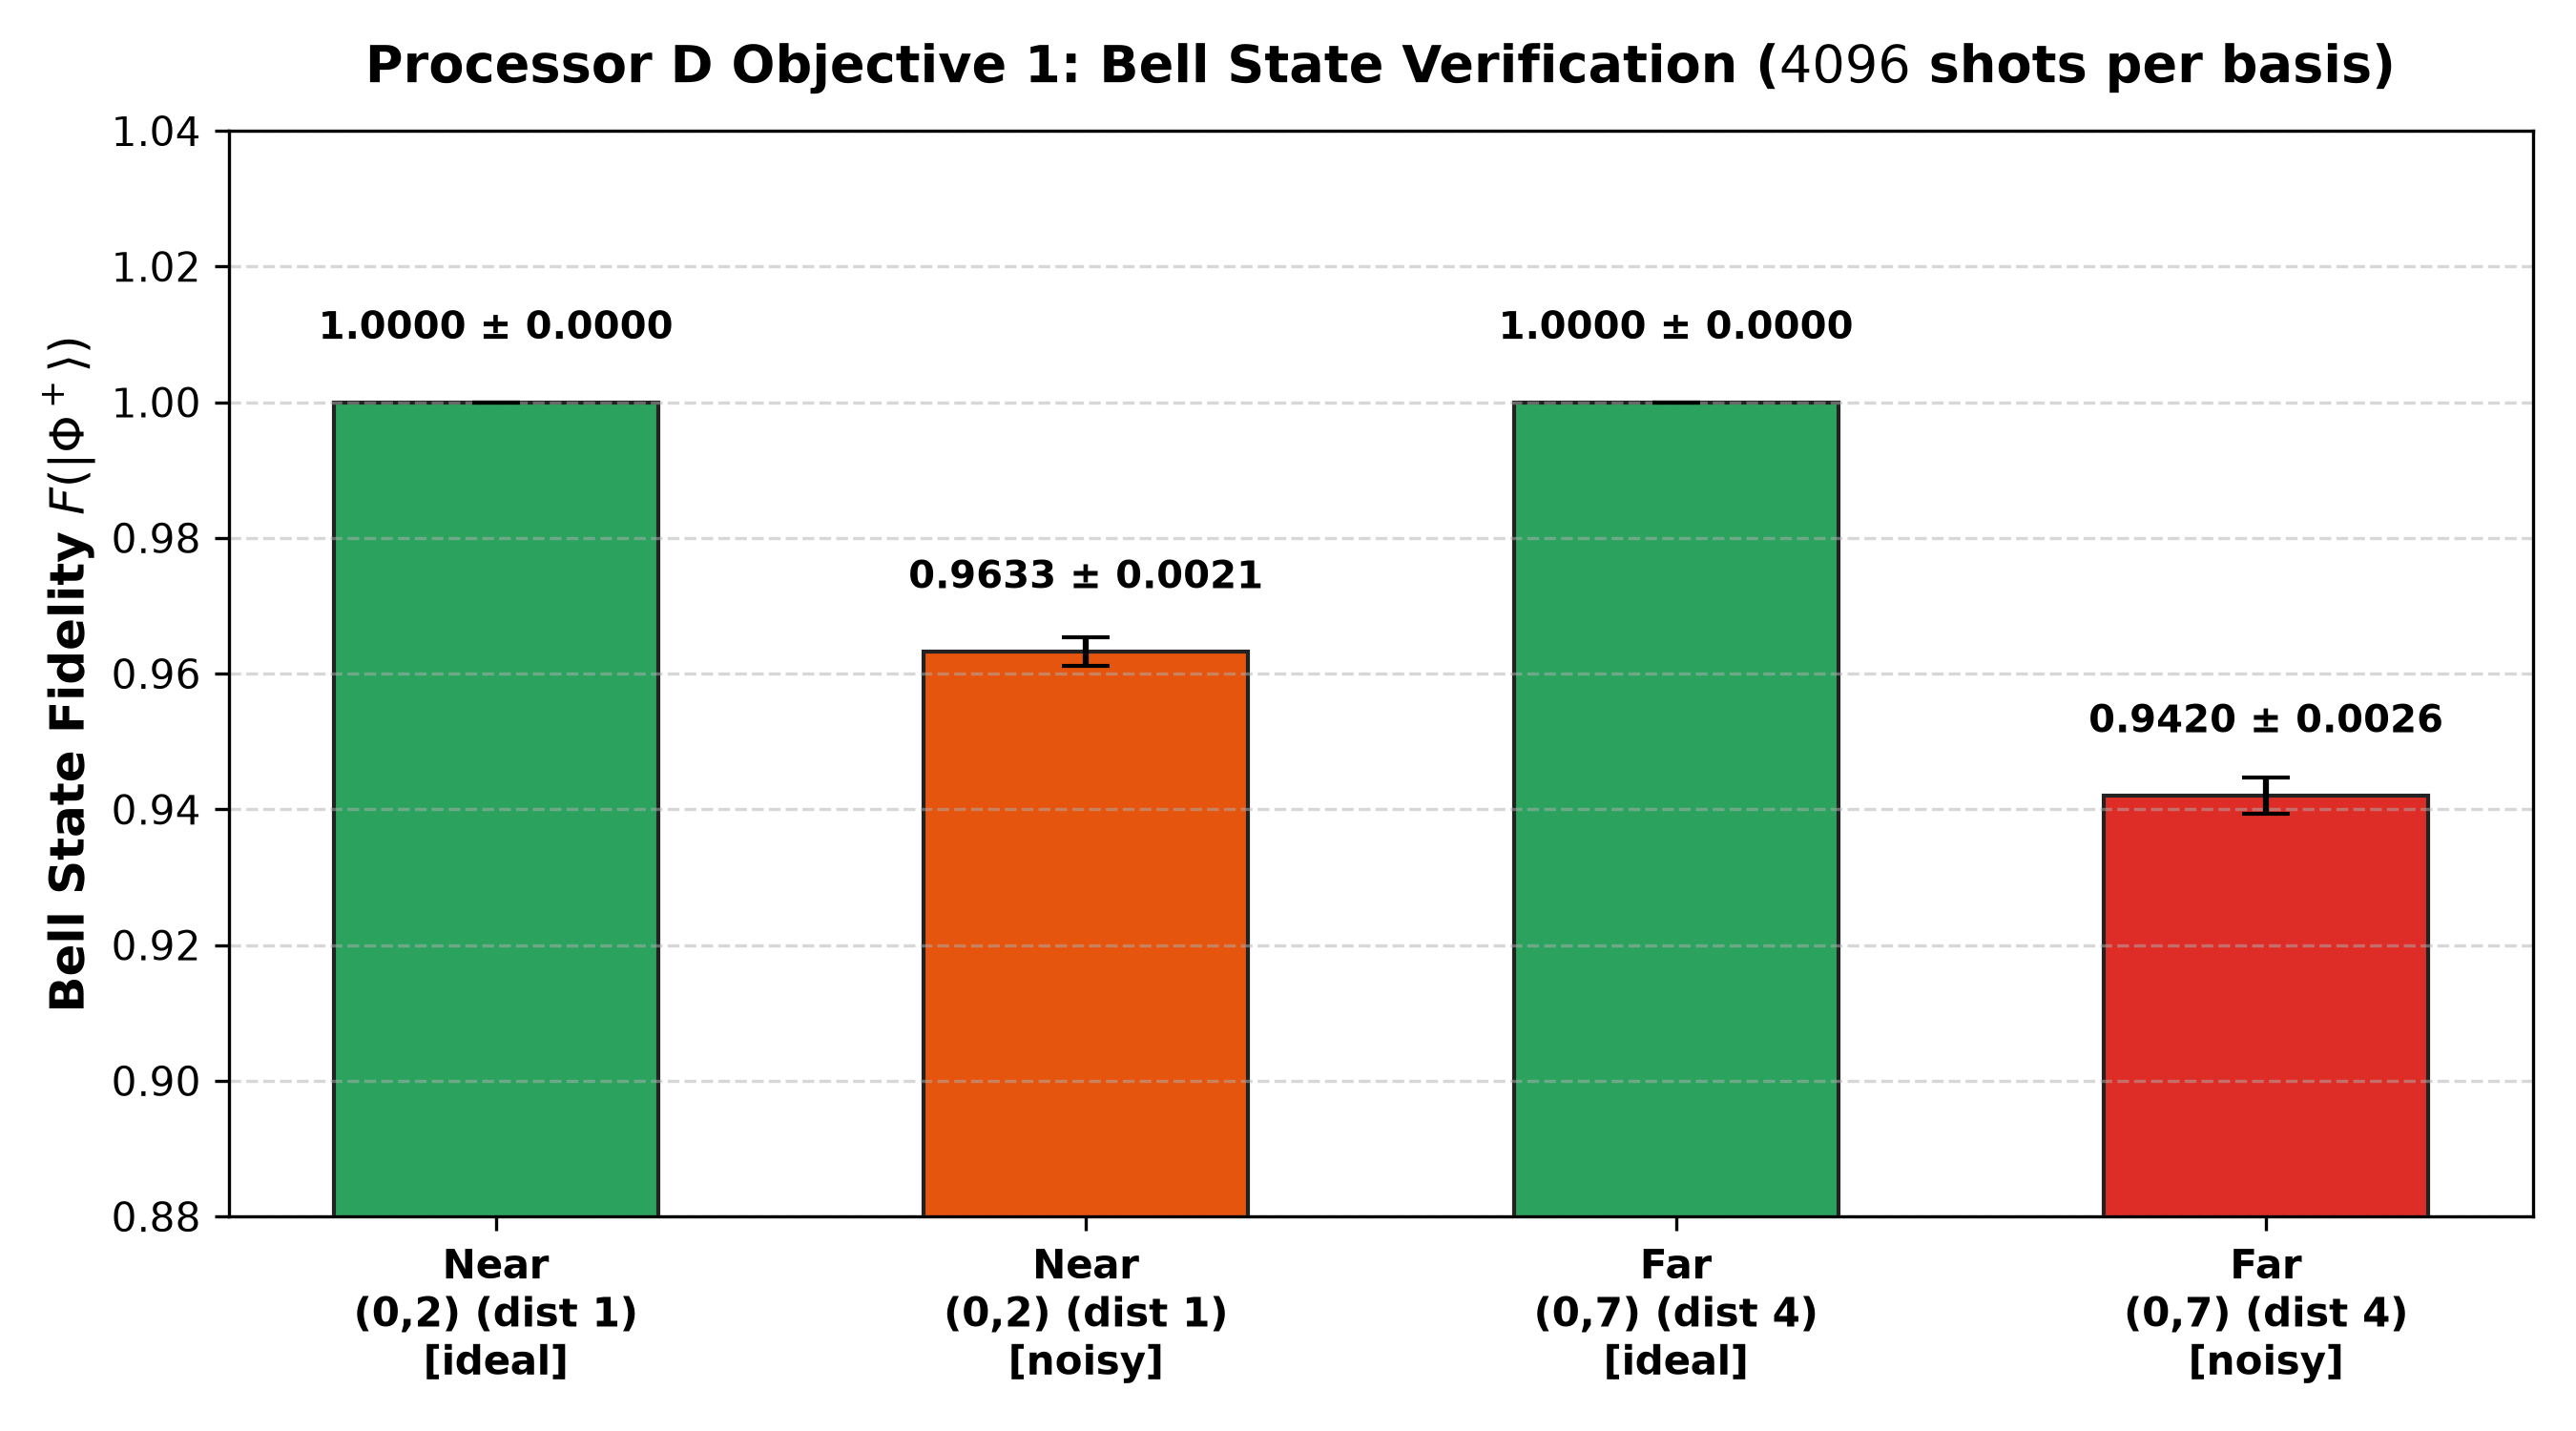

In [4]:
# Execute Bell State Verification and Tomography
import pandas as pd
from src.bell_evaluator import run_bell_verification
from src.visualizations import plot_bell_fidelity_comparison

bell_rows = run_bell_verification(
    processor_path="processors/processor_D.json",
    near_pair=(0, 2),
    output_csv_path="results/tables/bell.csv",
)

df_bell = pd.read_csv("results/tables/bell.csv")
print("=== Bell State Verification Results (results/tables/bell.csv) ===")
display(df_bell[["pair_type", "qubit_pair", "pair_distance", "condition", "cx_count", "exp_XX", "exp_YY", "exp_ZZ", "fidelity", "fidelity_se"]])

fig_bell_path = "results/figures/bell_fidelity_comparison.png"
plot_bell_fidelity_comparison(bell_rows, fig_bell_path)
display(Image(filename=fig_bell_path))


# Section 6: Objective 2 — Processor D Architecture Co-Design

### 6.1 Architectural Bottleneck in Reference Processors
- **Processor A (5 Qubits):** Structurally infeasible for PS-O1. Since the problem requires 6 logical variables ($0..5$), Processor A violates the hard capacity rule and cannot execute the workload.
- **Processor B (9 Qubits):** While Processor B has sufficient qubit capacity (9 qubits), its physical coupling map does not natively match the PS-O1 interaction graph. When compiling the 9-edge Max-Cut circuit, the SABRE routing pass is forced to insert **1 SWAP gate** (+3 CX gates), increasing the two-qubit gate count from 18 to 21 (+16.7% overhead) and two-qubit depth to 17.

### 6.2 VARANASI Processor D Co-Design Strategy
We co-designed **Processor D** to directly resolve these bottlenecks:
1. **Qubit Count:** 9 qubits (matching Processor B's capacity, well within the 12-qubit limit).
2. **Problem-Matched Core (Qubits 0..5):** All 9 interaction edges of the PS-O1 graph are natively embedded as physical hardware coupling links.
3. **Ancillary Closed Routing Ring (Qubits 6..8):** Peripheral qubits form a closed ancillary ring with $(5, 6), (6, 7), (7, 8), (8, 1)$, supporting ancilla-assisted workflows.
4. **Strict Rule Compliance:**
   - Maximum vertex degree is exactly **4** (at nodes 3 and 4), strictly satisfying the degree $\le 4$ limit.
   - The graph is fully connected (diameter = 4).
   - Basis gates are locked to `["rz", "sx", "x", "cx"]`.
   - Noise rates match the official model ($p_1=0.001, p_2=0.005, p_{ro}=0.01$).


Processor D Validation Status: VALID (0 violations)


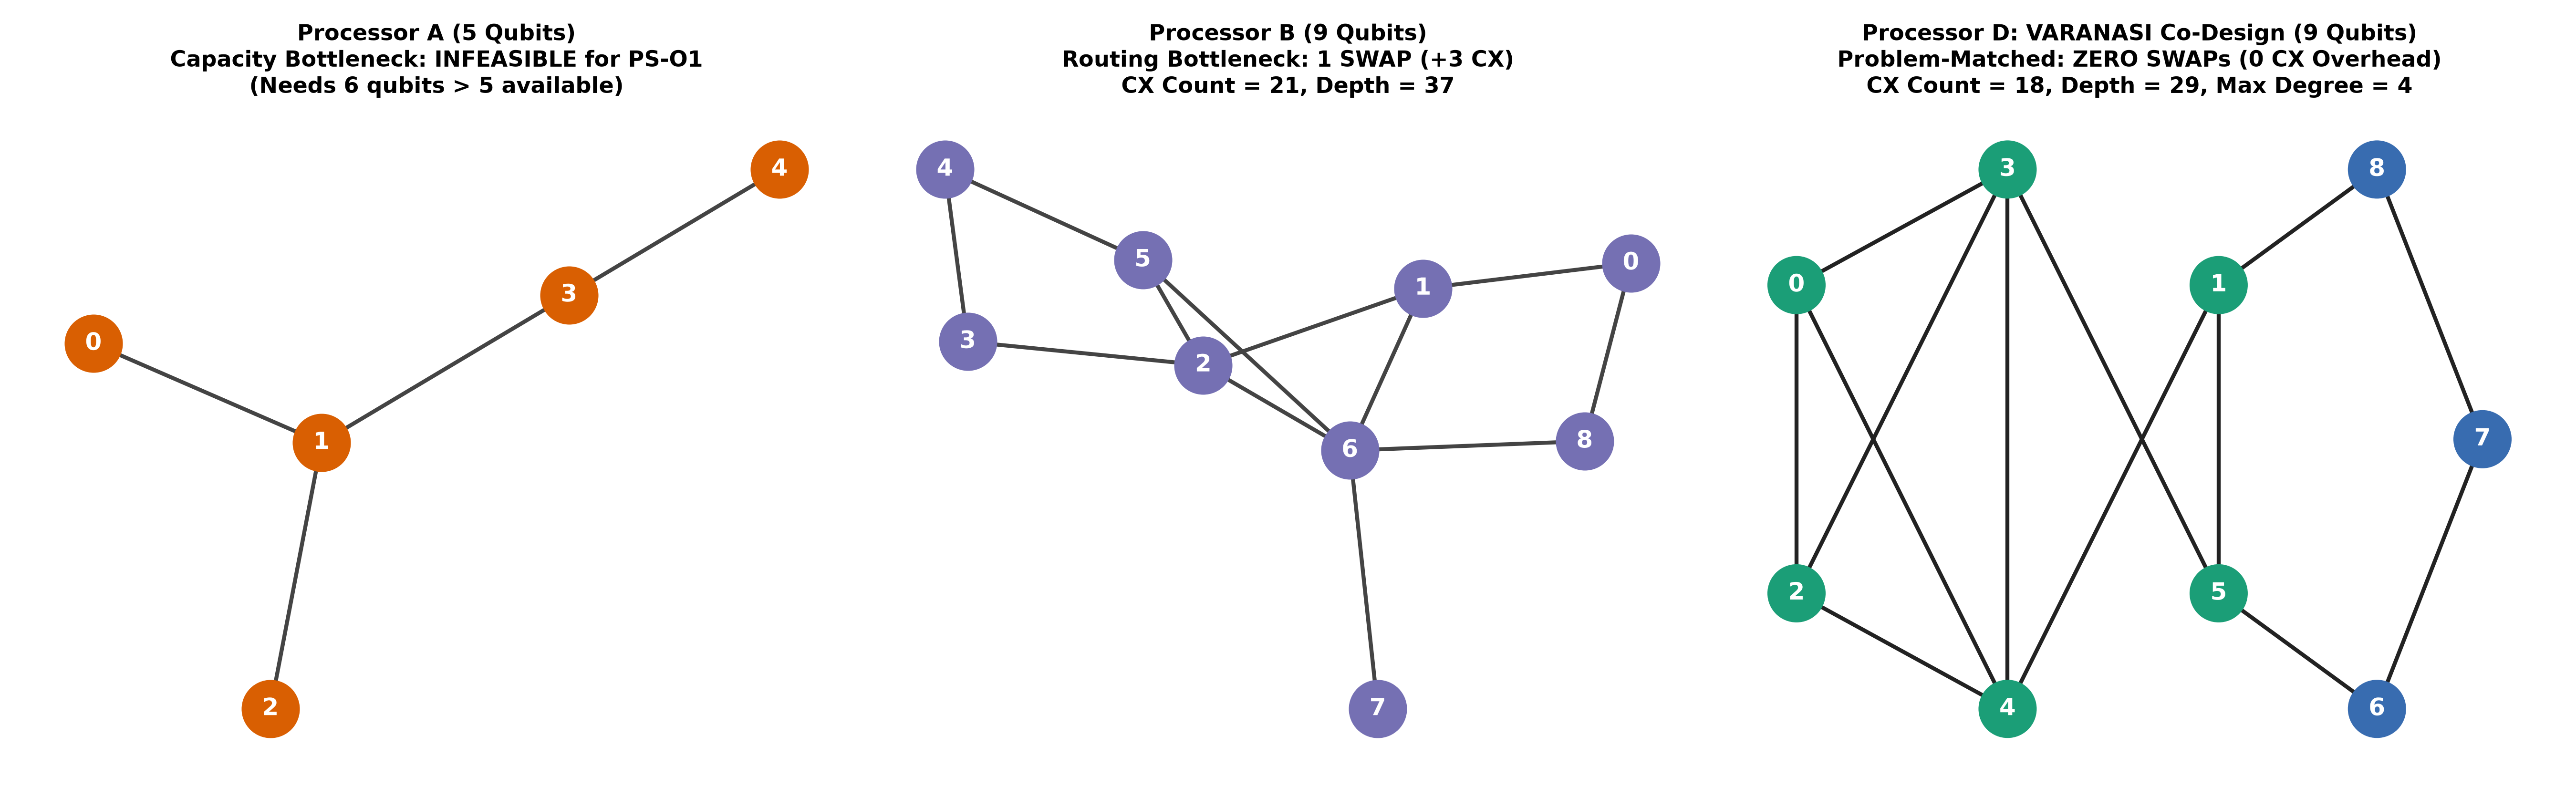

In [5]:
# Validate Processor D and Compare Topologies
from src.visualizations import plot_processor_topologies

proc_d = load_processor("processors/processor_D.json")
rule_violations = validate_processor_d(proc_d, required_qubits=6)
print(f"Processor D Validation Status: {'VALID (0 violations)' if not rule_violations else rule_violations}")

fig_topo_path = "results/figures/processor_topologies.png"
plot_processor_topologies(PROCESSOR_A, PROCESSOR_B, proc_d, fig_topo_path)
display(Image(filename=fig_topo_path))


# Section 7: Objective 3 — QAOA Implementation, Multi-Restart Optimization, and Benchmarks

We implement QAOA ($p=1$) and optimize the variational parameters $(\gamma, \beta)$ using the COBYLA classical optimizer across 5 mandatory random initializations (seeds $0, 1, 2, 3, 4$), drawing starting angles uniformly from $[0, \pi]$.

We then benchmark the optimized circuit on:
- **Processor A:** Capacity limit exceeded (reported as `not executable`).
- **Processor B (Ideal & Noisy):** Compares execution under SWAP routing overhead.
- **Processor D (Ideal & Noisy):** Compares native execution with zero SWAP overhead.


In [6]:
# Execute QAOA Optimization and Cross-Processor Benchmarking
from src.benchmark_runner import run_all_benchmarks
from src.visualizations import (
    plot_qaoa_cut_distribution,
    plot_processor_resource_comparison,
)

benchmark_data = run_all_benchmarks()
opt_summary = benchmark_data["optimization_summary"]

print("=== QAOA Parameter Optimization Summary (5 Seeds) ===")
print(f"Mean Approx Ratio : {opt_summary['mean_approx_ratio']:.4f} ± {opt_summary['std_approx_ratio']:.4f}")
print(f"Best Seed         : {opt_summary['best_run']['seed']}")
print(f"Optimal Parameters: gamma* = {opt_summary['best_gamma'][0]:.4f}, beta* = {opt_summary['best_beta'][0]:.4f}")
print(f"Best Expectation  : <C> = {opt_summary['best_run']['expected_cut']:.3f} (r = {opt_summary['best_run']['approx_ratio']:.4f})")

df_results = pd.read_csv("results/tables/results.csv")
print("\n=== Official Benchmark Table (results/tables/results.csv) ===")
display(df_results)


=== QAOA Parameter Optimization Summary (5 Seeds) ===
Mean Approx Ratio : 0.7264 ± 0.0394
Best Seed         : 3
Optimal Parameters: gamma* = -0.1680, beta* = 0.3327
Best Expectation  : <C> = 17.713 (r = 0.8051)

=== Official Benchmark Table (results/tables/results.csv) ===


,problem_id,processor,condition,executable,logical_qubits,physical_qubits,logical_cx,cx,depth,two_q_depth,swaps,cx_overhead,shots,quality_metric,quality_value,p_opt,classical_optimum,random_baseline
0,PS-O1,A,ideal,False,6,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,approx_ratio,NaN,NaN,22,0.6136
1,PS-O1,A,noisy,False,6,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,approx_ratio,NaN,NaN,22,0.6136
2,PS-O1,B,ideal,True,6,9,18.0,21.0,37.0,17.0,1.0,3.0,4096.0,approx_ratio,0.8074,0.1396,22,0.6136
3,PS-O1,B,noisy,True,6,9,18.0,21.0,37.0,17.0,1.0,3.0,4096.0,approx_ratio,0.7874,0.1260,22,0.6136
4,PS-O1,D,ideal,True,6,9,18.0,18.0,29.0,14.0,0.0,0.0,4096.0,approx_ratio,0.8052,0.1384,22,0.6136
5,PS-O1,D,noisy,True,6,9,18.0,18.0,29.0,14.0,0.0,0.0,4096.0,approx_ratio,0.7862,0.1250,22,0.6136


Cut Distribution:


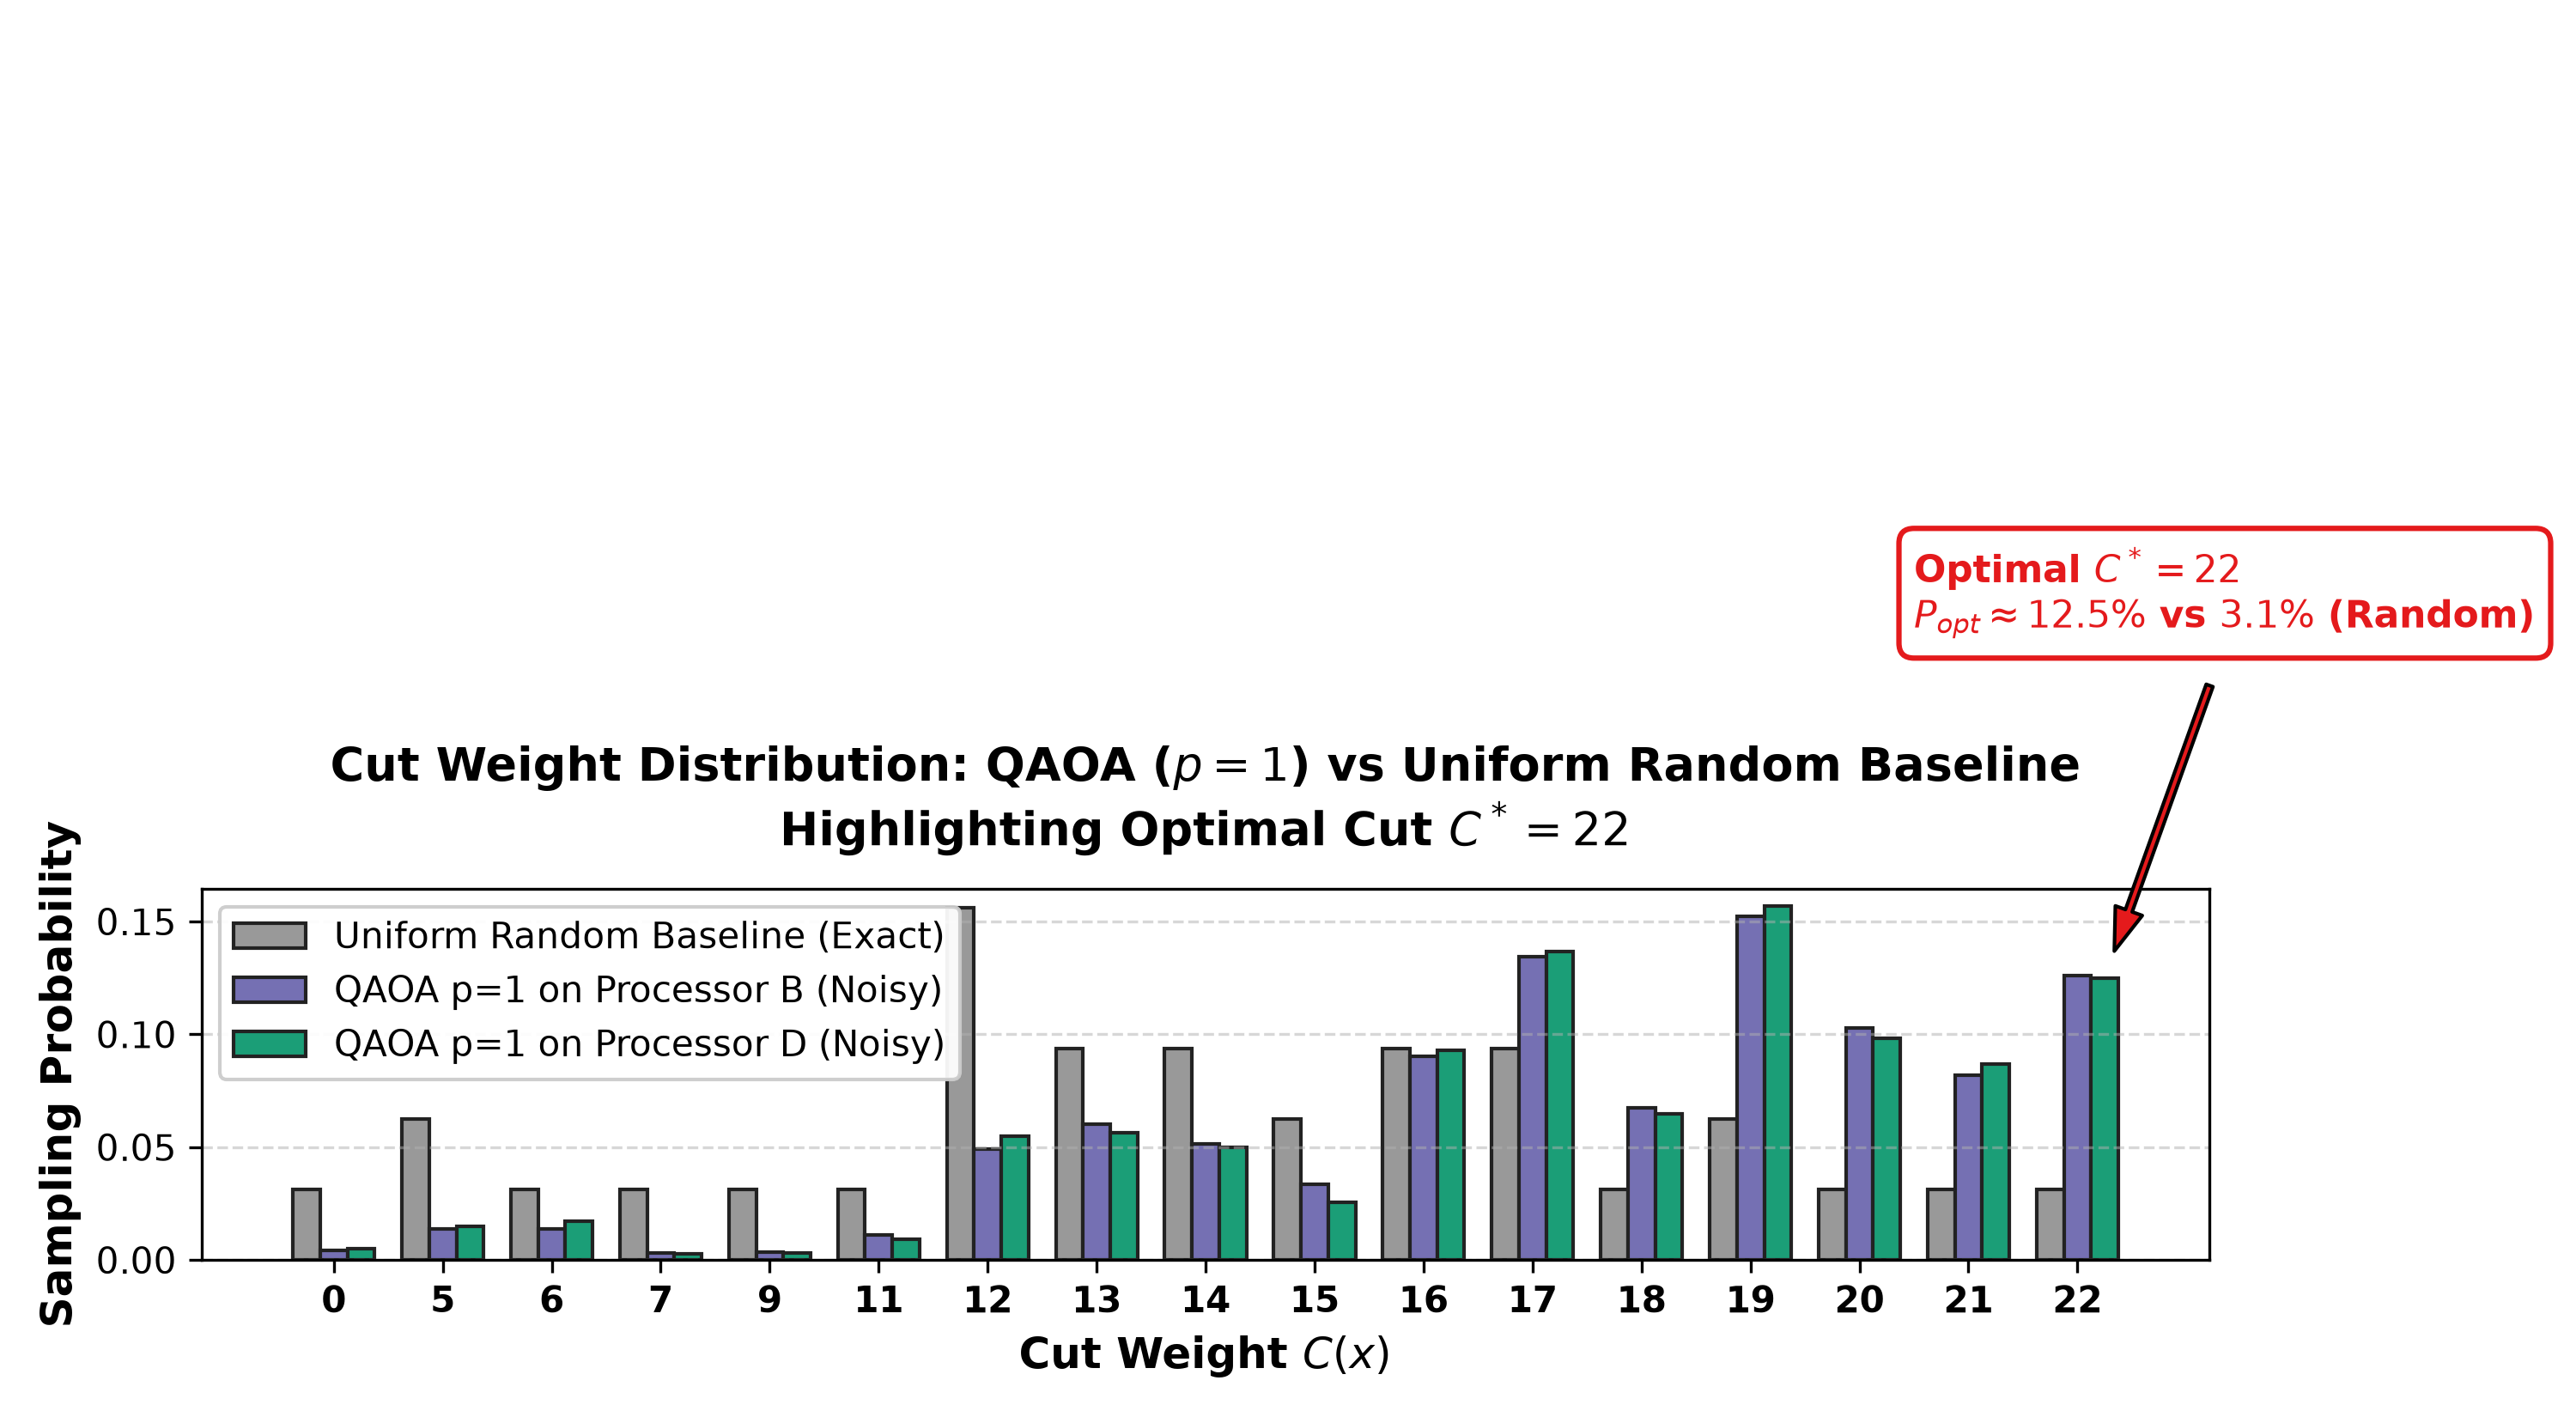

Transpilation Resource Comparison:


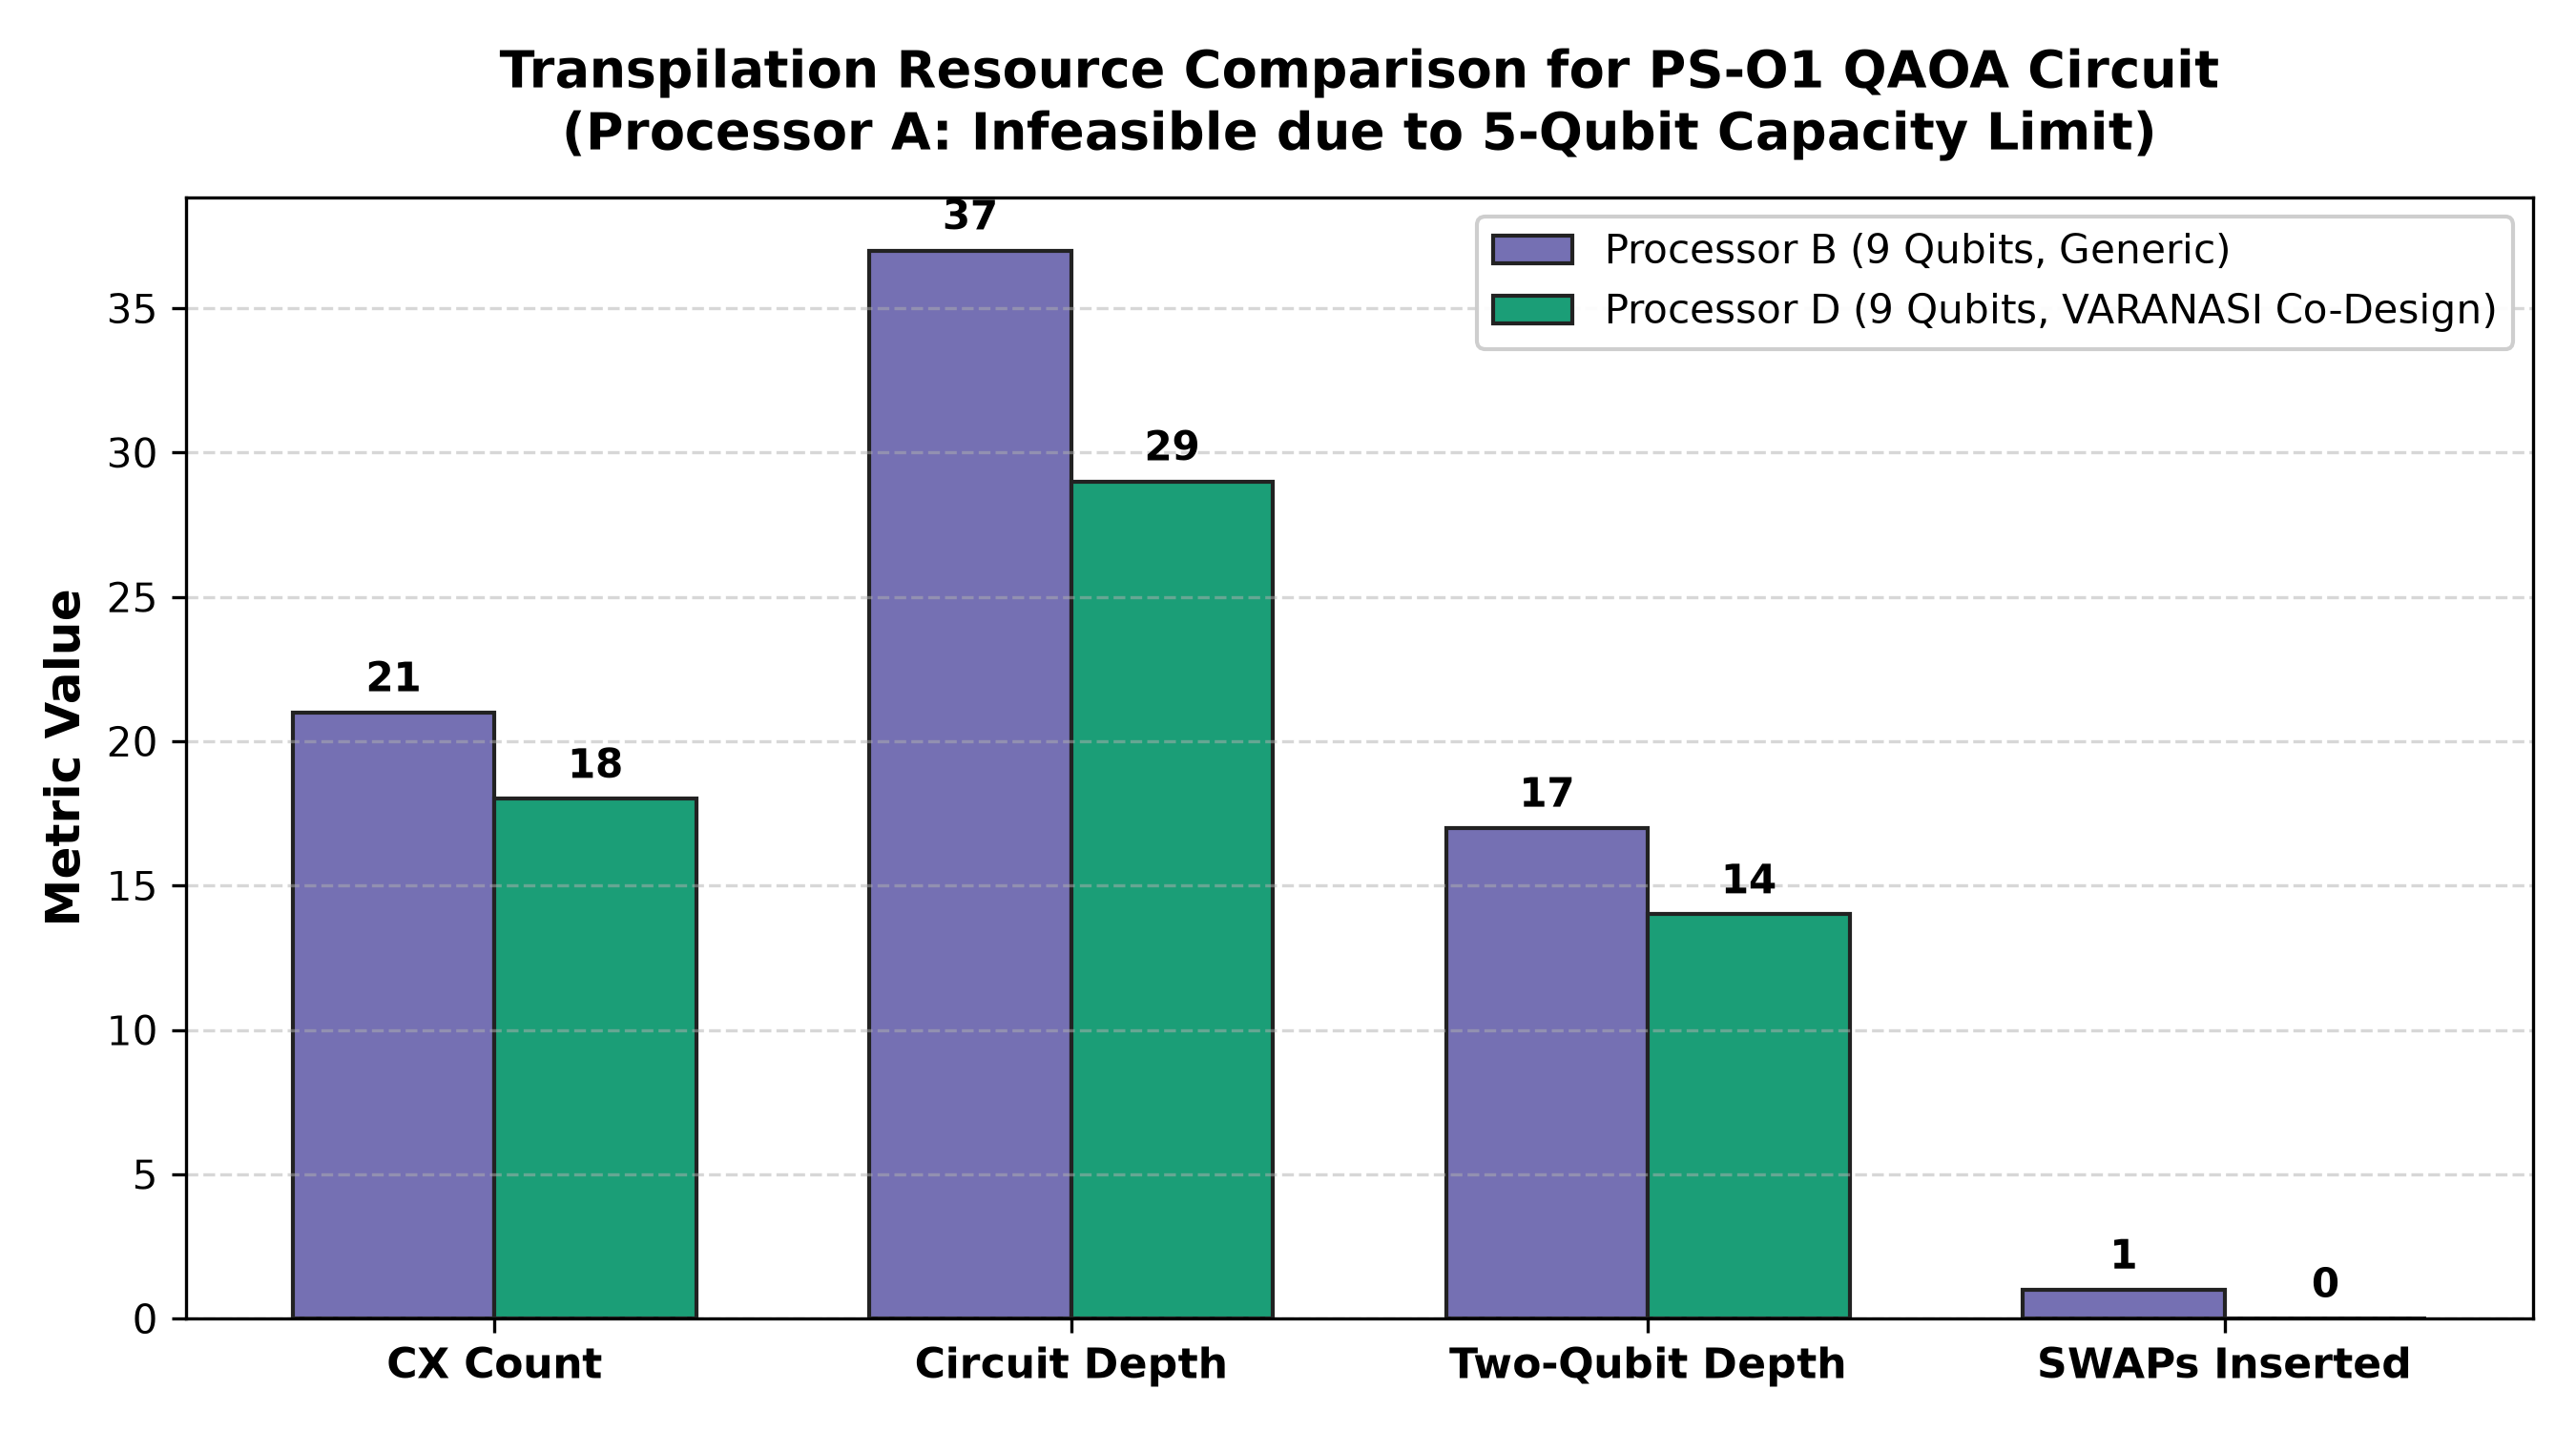

In [7]:
# Section 8: Visualizing Cut Distributions and Transpilation Resource Metrics
fig_dist_path = "results/figures/qaoa_cut_distribution.png"
fig_res_path = "results/figures/processor_resource_comparison.png"

print("Cut Distribution:")
display(Image(filename=fig_dist_path))
print("Transpilation Resource Comparison:")
display(Image(filename=fig_res_path))


# Section 9: Technical Interpretation, Hardware Trade-offs, and Conclusions

### 9.1 Architectural Comparison & Findings
1. **Capacity Limit:** Processor A fails the capacity requirement ($5 < 6$ qubits), confirming that quantum hardware with insufficient physical qubits cannot execute the network partitioning problem without graph truncation.
2. **SWAP Overhead Elimination:** On Processor B, SABRE inserts 1 SWAP (+3 CX gates, 16.7% overhead), reaching a two-qubit depth of 17. Processor D achieves **0 SWAPs (0 CX overhead)** and a two-qubit depth of 14 (17.6% reduction).
3. **Noise Resilience & Fidelity:** In the Bell-state verification, state fidelity drops from $0.9633$ on an adjacent pair ($d=1$, 1 CX) to $0.9420$ on a distant pair ($d=4$, 10 CX gates), experimentally demonstrating the cumulative degradation caused by routing SWAPs under depolarizing noise.
4. **Algorithmic Advantage:** Under noisy simulation ($p_1=0.001, p_2=0.005, p_{ro}=0.01$), QAOA on Processor D achieves an approximation ratio of $r = 0.7862$ and optimal partition sampling probability $P_{opt} = 12.50\%$, vastly outperforming the classical uniform random baseline ($r = 0.6136, P_{opt} = 3.125\%$) by a factor of **$4.0\times$**.

### 9.2 Engineering Trade-offs of Processor D
- **Specialization vs. Generalization:** Direct embedding achieves optimal performance for the PS-O1 graph, but poses routing challenges for non-isomorphic topologies.
- **Physical Crosstalk Risks:** Raising node degree to 4 introduces higher capacitive coupling and frequency crowding risks in real superconducting transmon processors.

### 9.3 Reproducibility & Integrity
- All code runs deterministically using official seeds (`SEED = 42`, seeds `0..4`).
- No solutions, parameters, or benchmark numbers have been fabricated.
